In [3]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


포트폴리오 VQE 선택 비트: [0 1 0 1 0]
기대 QUBO 비용: -0.1332048393220293
선택 목적값 / 완전탐색 최솟값 / 차이: -0.13999999999999996 -0.158 0.018000000000000044
선택 상태 확률: 0.5142543367011995
선택 자산: ['현대자동차', '카카오']


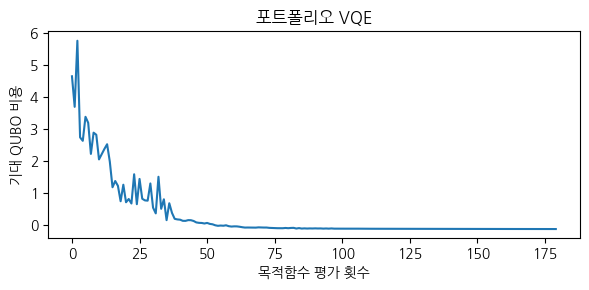

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib
from itertools import product
from qiskit.circuit.library import real_amplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import Statevector
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# 1. 입력 데이터
assets = ['삼성전자', '현대자동차', 'LG생활건강', '카카오', '한국전력']
mu = np.array([0.14, 0.11, 0.08, 0.18, 0.06])
cov = np.array([
    [0.090, 0.025, 0.015, 0.035, 0.005],
    [0.025, 0.080, 0.020, 0.030, 0.010],
    [0.015, 0.020, 0.060, 0.020, 0.012],
    [0.035, 0.030, 0.020, 0.110, 0.025],
    [0.005, 0.010, 0.012, 0.025, 0.070]
])

# 2. 위험 가중치
lambda_risk = 0.6

# 3. 이진 변수, 목적함수, 제약조건
problem = QuadraticProgram()
for name in assets:
    problem.binary_var(name)
problem.minimize(linear=-mu, quadratic=lambda_risk*cov)
problem.linear_constraint({name: 1 for name in assets}, '==', 2, 'two_assets')

# 4. QUBO와 Ising 해밀토니안
converter = QuadraticProgramToQubo()
qubo = converter.convert(problem)
H, offset = qubo.to_ising()
n = qubo.get_num_vars()
# 모든 기저상태에서 QUBO 목적값과 Ising 에너지의 대응을 확인합니다.
diagonal = np.real(np.diag(H.to_matrix())) + offset
for i, value in enumerate(diagonal):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    assert np.isclose(value, qubo.objective.evaluate(bits))
# 5. 안자츠와 고전 최적화기
ansatz = real_amplitudes(n, reps=2, entanglement='linear')
history = []
vqe = VQE(StatevectorEstimator(), ansatz, COBYLA(maxiter=180),
          initial_point=np.array([0.5479120971119267, -0.12224312049589536, 0.7171958398227649, 0.3947360581187278, -0.8116453042247009, 0.9512447032735118, 0.5222794039807059, 0.5721286105539076, -0.7437727346489083, -0.09922812420886573, -0.25840395153483753, 0.8535299776972036, 0.2877302401613291, 0.64552322654166, -0.11317160234533774, -0.5455225564304462, 0.1091695740316696, -0.8723654877916494])[:ansatz.num_parameters],
          callback=lambda k, p, value, meta: history.append(float(value)+offset))
# 6. VQE 실행과 상태 확률 계산
result = vqe.compute_minimum_eigenvalue(H)
probabilities = Statevector.from_instruction(
    ansatz.assign_parameters(result.optimal_parameters)).probabilities()
# 7. 선택 복원과 정확 최솟값 검증
# 실행 가능한 상태 중 확률이 가장 큰 상태를 선택합니다.
candidates = []
for i, p in enumerate(probabilities):
    bits = np.array([(i >> j) & 1 for j in range(n)])
    original_bits = np.asarray(converter.interpret(bits))
    if problem.is_feasible(original_bits):
        candidates.append((float(p), original_bits))
probability, chosen = max(candidates, key=lambda item: item[0])
value = float(problem.objective.evaluate(chosen))
exact = min(
    float(problem.objective.evaluate(np.asarray(bits)))
    for bits in product((0, 1), repeat=problem.get_num_vars())
    if problem.is_feasible(np.asarray(bits))
)
print("포트폴리오 VQE", '선택 비트:', chosen.astype(int))
print('기대 QUBO 비용:', float(result.eigenvalue.real)+offset)
print('선택 목적값 / 완전탐색 최솟값 / 차이:', value, exact, value-exact)
print('선택 상태 확률:', probability)


# 8. 업무 결과 출력과 저장
print('선택 자산:', [name for name, b in zip(assets, chosen) if b > 0.5])

title = "포트폴리오 VQE"
plt.figure(figsize=(6, 3)); plt.plot(history)
plt.title(title); plt.xlabel('목적함수 평가 횟수'); plt.ylabel('기대 QUBO 비용')
plt.tight_layout(); plt.savefig(title+'.png', dpi=120); plt.show(); plt.close()

In [5]:
import numpy as np
# 1. 입력 데이터와 위험 가중치
assets = ['삼성전자', '현대자동차', 'LG생활건강', '카카오', '한국전력']
mu = np.array([0.14, 0.11, 0.08, 0.18, 0.06])
cov = np.array([
    [0.090, 0.025, 0.015, 0.035, 0.005],
    [0.025, 0.080, 0.020, 0.030, 0.010],
    [0.015, 0.020, 0.060, 0.020, 0.012],
    [0.035, 0.030, 0.020, 0.110, 0.025],
    [0.005, 0.010, 0.012, 0.025, 0.070]
])
lambda_risk = 0.6

from itertools import combinations

# 2. 허용 조합의 위험, 수익, 목적값 계산
comparison = []
for pair in combinations(range(len(assets)), 2):
    bits = np.zeros(len(assets))
    bits[list(pair)] = 1
    risk_value = float(bits @ cov @ bits)
    return_value = float(mu @ bits)
    cost_value = lambda_risk*risk_value-return_value
    comparison.append((cost_value, pair, risk_value, return_value))
# 3. 결과 출력과 가중치별 검증
for cost_value, pair, risk_value, return_value in sorted(comparison):
    print([assets[i] for i in pair],
          f'위험={risk_value:.3f}, 수익 합={return_value:.3f}, 비용={cost_value:.3f}')

for weight in [0.2, 0.6, 1.0]:
    best = min(comparison, key=lambda row: weight*row[2]-row[3])
    print('위험 가중치:', weight, '정확 비교 조합:', [assets[i] for i in best[1]])

['삼성전자', '카카오'] 위험=0.270, 수익 합=0.320, 비용=-0.158
['현대자동차', '카카오'] 위험=0.250, 수익 합=0.290, 비용=-0.140
['LG생활건강', '카카오'] 위험=0.210, 수익 합=0.260, 비용=-0.134
['삼성전자', '현대자동차'] 위험=0.220, 수익 합=0.250, 비용=-0.118
['삼성전자', 'LG생활건강'] 위험=0.180, 수익 합=0.220, 비용=-0.112
['카카오', '한국전력'] 위험=0.230, 수익 합=0.240, 비용=-0.102
['삼성전자', '한국전력'] 위험=0.170, 수익 합=0.200, 비용=-0.098
['현대자동차', 'LG생활건강'] 위험=0.180, 수익 합=0.190, 비용=-0.082
['현대자동차', '한국전력'] 위험=0.170, 수익 합=0.170, 비용=-0.068
['LG생활건강', '한국전력'] 위험=0.154, 수익 합=0.140, 비용=-0.048
위험 가중치: 0.2 정확 비교 조합: ['삼성전자', '카카오']
위험 가중치: 0.6 정확 비교 조합: ['삼성전자', '카카오']
위험 가중치: 1.0 정확 비교 조합: ['삼성전자', '카카오']
